# TweetEval – Offensive Language Detection
## Notebook 05 · Model Training (required models + optional models)

### What the assignment asks
> Each group must test **at least five different models** among: Logistic Regression · SVM · Random Forest · Naive Bayes · KNN · *(optional: advanced models such as LSTM or BERT)*.

This notebook trains **all five required models**, then adds **optional models** to go further. Every model has its own file in `src/`:

| # | Model | Type | File in `src/` | Status |
|---|---|---|---|---|
| 1 | Logistic Regression | linear | `logistic_regression.py` | required |
| 2 | SVM (LinearSVC) | linear | `svm.py` | required |
| 3 | Random Forest | trees ensemble | `random_forest.py` | required |
| 4 | Naive Bayes | probabilistic | `naive_bayes.py` | required |
| 5 | KNN | distance based | `knn.py` | required |
| 6 | Complement NB · SGD · Voting ensemble | classical extras | `extra_models.py` | optional |
| 7 | **BiLSTM** | deep learning (sequence) | `lstm_model.py` | optional (needs `torch`) |
| 8 | **BERT / DistilBERT** | Transformer fine-tuning | `bert_model.py` | optional (needs `torch`, `transformers`, GPU advised) |

Shared helpers: `model_utils.py` (grid search, oversampling, scores) and `torch_utils.py` (training loop of the two neural models).

### Rules applied to every model (fair comparison)
* one seed (`config.RANDOM_STATE`) · TF-IDF fitted on **train only** · hyperparameters chosen on **validation**, criterion = **F1 of the offensive class** · the **test set is never used** here;
* imbalance (about 1 offensive tweet in 3) handled **without altering the validation data**, following the decision of notebook 04 (`class_weight`, with equivalents for models that have none).

### Metrics reminder (offensive = positive class)
* **Precision** = of the tweets flagged offensive, how many really are? (few false alarms)
* **Recall** = of the truly offensive tweets, how many did we catch? (few misses)
* **F1** = harmonic mean of precision and recall → our **main criterion** (accuracy is inflated by the majority class).
* **Average precision (AP)** = area under the precision-recall curve: compares models **independently of the 0.5 threshold**.

### Contents
1. [Setup and switches](#1) · 2. [Data and features](#2) · 3. [Logistic Regression](#3) · 4. [SVM](#4) · 5. [Random Forest](#5) · 6. [Naive Bayes](#6) · 7. [KNN](#7) ·
8. [Optional classical models](#8) · 9. [Optional: BiLSTM](#9) · 10. [Optional: BERT](#10) · 11. [Comparison](#11) · 12. [Cross-validation](#12) · 13. [What the linear models learned](#13) · 14. [Conclusions](#14) · 15. [Saving](#15)

> Each result cell is followed by a **Reading** cell explaining how to interpret it.

<a id="1"></a>
## 1. Setup and switches
Three switches control the slow / optional parts. **The five required models always run.**

| Switch | Meaning |
|---|---|
| `RUN_EXTRA` | classical optional models (seconds) |
| `RUN_LSTM`, `RUN_BERT` | `True` = run, `False` = skip, `"auto"` = run only if `torch` is installed **and** a GPU is available (so a laptop without GPU never blocks for an hour) |
| `RUN_CV` | 5-fold cross-validation of the classical models (a few minutes) |

In [35]:
import sys, warnings                              # sys: python import path | warnings: hide noisy warnings
from pathlib import Path                           # OS-independent file paths

import numpy as np                                 # numerical arrays
import pandas as pd                                # tables
import matplotlib.pyplot as plt                    # plots
import seaborn as sns                              # nicer plot defaults
from sklearn.metrics import (ConfusionMatrixDisplay,      # draws a confusion matrix
                             average_precision_score,     # AP: threshold-free ranking quality
                             precision_recall_curve)      # points of the PR curve
from sklearn.model_selection import StratifiedKFold      # CV folds that keep the class ratio

warnings.filterwarnings("ignore")                  # keep the notebook readable
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110                   # sharper figures
pd.set_option("display.max_colwidth", 120)

# Project root: works whether Jupyter was started in the root folder or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                      # lets Python import the `src` package

# ---- shared project modules (same ones as notebooks 03 and 04) --------------------
from src import config                                              # seed, TF-IDF parameters, BALANCING decision
from src.utils import setup_paths, savefig                          # standard output folders + figure saving
from src.features import fit_tfidf, transform_tfidf                 # fit on train / transform other sets
from src.evaluation import compute_metrics, get_confusion_matrix   # accuracy, precision, recall, F1 + confusion matrix
# ---- one file per model ------------------------------------------------------------
from src import logistic_regression, svm, random_forest, naive_bayes, knn
from src import extra_models, lstm_model, bert_model, torch_utils
from src.model_utils import get_scores, oversample, top_linear_terms

# ---------------------------- SWITCHES ----------------------------------------------
RUN_EXTRA = True            # Complement NB, SGD, Voting ensemble
RUN_LSTM  = "auto"          # True / False / "auto"  (auto = torch installed AND GPU present)
RUN_BERT  = "auto"          # True / False / "auto"  (set True on Google Colab with a GPU)
RUN_CV    = True            # 5-fold cross-validation (section 12)

def _enabled(flag):
    """Resolve True / False / 'auto' (auto = torch + GPU available)."""
    if flag == "auto":
        return torch_utils.TORCH_OK and torch_utils.torch.cuda.is_available()
    return bool(flag)

P = setup_paths("05_model_training")               # folders: results/{figures,metrics}/05_model_training/
PRED_DIR = P.root / "results" / "predictions" / "05_model_training"
MODEL_DIR = P.root / "models"                      # NEW: saved neural models (loaded by notebook 06)
for d in (P.figures, P.metrics, PRED_DIR, MODEL_DIR):
    Path(d).mkdir(parents=True, exist_ok=True)     # create the output folders if missing

SEED = config.RANDOM_STATE                         # ONE seed for the whole project
COLORS = {"non-offensive": "#4C78A8", "offensive": "#E45756"}        # class colours
MODEL_COLORS = {"Logistic Regression": "#54A24B", "SVM (LinearSVC)": "#72B7B2", "Random Forest": "#F58518",
                "Naive Bayes": "#B279A2", "KNN": "#9D755D", "Complement NB": "#D4A6C8",
                "SGD (modified Huber)": "#9ECAE9", "Voting ensemble": "#BAB0AC",
                "BiLSTM": "#E15759", "BERT": "#EDC948"}              # one colour per model

print("Root          :", P.root)
print("Seed          :", SEED)
print("torch present :", torch_utils.TORCH_OK, "| GPU:", torch_utils.TORCH_OK and torch_utils.torch.cuda.is_available())
print("Run optional  : extra =", RUN_EXTRA, "| LSTM =", _enabled(RUN_LSTM), "| BERT =", _enabled(RUN_BERT), "| CV =", RUN_CV)

Root          : C:\Users\ASUS\Desktop\TweetEval-offensiveML
Seed          : 42
torch present : True | GPU: True
Run optional  : extra = True | LSTM = True | BERT = True | CV = True


**Reading.** The last lines show what will actually run. If `torch present` is `False` or there is no GPU, the LSTM and BERT sections are skipped automatically
(you can still force them with `True`, or run them on Google Colab). The required models never depend on these switches.

<a id="2"></a>
## 2. Data and features
We read the **final** files of notebook 03: `text_clean` (cleaned text, used by the TF-IDF models and the LSTM) and `text` (original tweet, used by BERT).
`keep_default_na=False` keeps empty cleaned tweets as empty strings (otherwise pandas turns them into `NaN` and TF-IDF fails).
**TF-IDF is fitted once on train only** and shared by all classical models.

### How each classical model handles the class imbalance
| Model | Strategy | Why |
|---|---|---|
| Logistic Regression, LinearSVC, Random Forest, SGD | `class_weight="balanced"` | notebook 04 decision: nothing duplicated or removed |
| Naive Bayes | equal priors `fit_prior=False` | no `class_weight` option; equal priors play the same role |
| Complement NB | built for imbalanced text | uses statistics of the *complement* of each class |
| KNN | random **oversampling** of the training offensive tweets | no `class_weight`; fallback of notebook 04 |
| BiLSTM, BERT | class-weighted cross-entropy loss | same idea as `class_weight`, inside the loss |

Only **training** rows are ever rebalanced; validation keeps its original distribution.

In [36]:
train_path, val_path = P.processed / "train_final.csv", P.processed / "val_final.csv"
for p in (train_path, val_path):                                  # friendly error if notebook 03 was not run
    assert p.exists(), f"{p.name} not found: run notebook 03 first (it creates the *_final.csv files)."

train = pd.read_csv(train_path, keep_default_na=False)            # cleaned train split
val   = pd.read_csv(val_path,   keep_default_na=False)            # cleaned validation split

# Original text for BERT; fall back to the cleaned text if the column is absent
RAW = "text" if {"text"} <= set(train.columns) and {"text"} <= set(val.columns) else "text_clean"
if RAW == "text_clean":
    print("WARNING: no 'text' column -> BERT will receive the cleaned text (less ideal).")

vec, X_train = fit_tfidf(train["text_clean"])                     # learn vocabulary + IDF on TRAIN only
X_val = transform_tfidf(vec, val["text_clean"])                   # val is only TRANSFORMED (no leakage)
y_train, y_val = train["label"].to_numpy(), val["label"].to_numpy()   # 0 = non-offensive, 1 = offensive
feature_names = vec.get_feature_names_out()                       # TF-IDF column -> word / bigram

print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print(f"offensive share  train = {100 * y_train.mean():.1f} %   val = {100 * y_val.mean():.1f} %")
print("TF-IDF settings :", config.TFIDF_PARAMS)

X_train: (11916, 17550) | X_val: (1324, 17550)
offensive share  train = 33.1 %   val = 34.7 %
TF-IDF settings : {'max_features': 20000, 'ngram_range': (1, 2), 'min_df': 2, 'token_pattern': "[a-z0-9'*]+"}


**Reading.** Train and validation have the same number of columns because the vocabulary comes from train only. The offensive share (about one third) is the imbalance handled above.
Because the TF-IDF matrix is shared, every classical model sees **exactly the same input**: score differences come from the algorithm, not from the data.

### The model registry
Every model, whatever its type, is stored in the dictionary `PRED` as **(predicted labels, continuous scores)** on the validation set.
Section 11 builds all tables and plots from this single dictionary, so adding a model never requires touching the comparison code.

In [37]:
PRED = {}        # name -> {"group": ..., "y_pred": ..., "scores": ..., "params": ...}  (insertion order = display order)
MODELS = {}      # name -> fitted sklearn estimator (only classical models; used for CV and top terms)

def register(name, y_pred, scores=None, group="required", params=None, model=None):
    """Store the validation predictions of one model (and the fitted estimator if there is one)."""
    PRED[name] = {"group": group, "y_pred": np.asarray(y_pred), "scores": scores, "params": params}
    if model is not None:
        MODELS[name] = model

def register_model(name, model, group="required", params=None):
    """Shortcut for a fitted scikit-learn model: predict on val, get its scores, register everything."""
    register(name, model.predict(X_val), get_scores(model, X_val), group, params, model)

def edge_warning(best, values, label):
    """Warn if the best value sits at the border of the grid (the grid may be too narrow)."""
    if best in (values[0], values[-1]):
        print(f"WARNING: best {label} is at the edge of the grid -> consider extending it.")

<a id="3"></a>
## 3. Model 1 · Logistic Regression  (`src/logistic_regression.py`)
**Idea.** A weighted sum of TF-IDF features is passed through a sigmoid to give P(offensive). Training finds the weights that best explain the labels.
**Hyperparameter `C`** = inverse regularisation strength: small `C` → simple model (underfitting risk), large `C` → flexible model (overfitting risk).
**Imbalance:** `class_weight="balanced"` makes mistakes on offensive tweets cost about twice as much.

In [38]:
# tune(): trains one model per value of C, keeps the best validation F1 (offensive class)
lr, best_lr_C, lr_grid = logistic_regression.tune(X_train, y_train, X_val, y_val)
print(f"Best C = {best_lr_C}  (F1 val = {lr_grid['F1 val (offensive)'].max():.4f})")
edge_warning(best_lr_C, logistic_regression.DEFAULT_C_GRID, "C")          # is the grid wide enough?
register_model(logistic_regression.NAME, lr, params={"C": best_lr_C})      # keep predictions for the comparison
display(lr_grid)                                                           # whole tuning table

Best C = 1  (F1 val = 0.6261)


,C,F1 val (offensive)
0,1.0,0.6261
1,3.0,0.6183
2,100.0,0.6075
3,10.0,0.6071
4,0.3,0.6059
5,30.0,0.5956
6,0.1,0.5903


**Reading.** A best `C` strictly *inside* the grid means the grid is wide enough (the warning would appear otherwise). Differences of one or two thousandths between neighbouring `C` are noise:
what matters is the overall shape (rise, plateau, then slight drop).

<a id="4"></a>
## 4. Model 2 · SVM / LinearSVC  (`src/svm.py`)
**Idea.** Find the separating hyperplane with the **largest margin** between the classes. With TF-IDF text a **linear** kernel is the standard choice (thousands of sparse dimensions, almost always linearly separable enough; RBF kernels are far slower with little gain).
**Hyperparameter `C`** again controls regularisation, but its best value is usually *smaller* than for Logistic Regression because the two loss functions are scaled differently.

In [39]:
svm_model, best_svm_C, svm_grid = svm.tune(X_train, y_train, X_val, y_val)    # same procedure, same criterion
print(f"Best C = {best_svm_C}  (F1 val = {svm_grid['F1 val (offensive)'].max():.4f})")
edge_warning(best_svm_C, svm.DEFAULT_C_GRID, "C")
register_model(svm.NAME, svm_model, params={"C": best_svm_C})
display(svm_grid)

Best C = 0.3  (F1 val = 0.6233)


,C,F1 val (offensive)
0,0.30,0.6233
1,0.10,0.6186
2,0.03,0.6039
3,3.00,0.5982
4,1.00,0.5938
5,0.01,0.5915


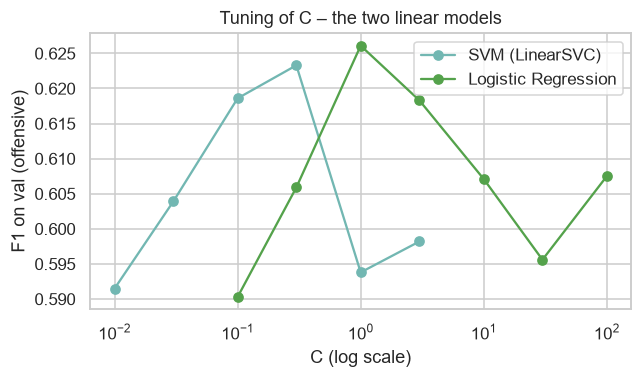

In [40]:
# Both linear models share the same C axis (log scale) so their curves can be compared directly
fig, ax = plt.subplots(figsize=(6, 3.6))
for name, tab in ((svm.NAME, svm_grid), (logistic_regression.NAME, lr_grid)):
    t = tab.sort_values("C")                                                  # increasing C for a clean line
    ax.plot(t["C"], t["F1 val (offensive)"], marker="o", color=MODEL_COLORS[name], label=name)
ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_ylabel("F1 on val (offensive)")
ax.set_title("Tuning of C – the two linear models"); ax.legend()
fig.tight_layout(); savefig(fig, P.figures / "linear_models_tuning_C.png"); plt.show()

**Reading.** Each curve should have an optimum with a decline on both sides: **underfitting** on the left (too much regularisation), **overfitting** on the right (too little). The optima sit at different `C` values, which is normal.

<a id="5"></a>
## 5. Model 3 · Random Forest  (`src/random_forest.py`)
**Idea.** Many decision trees, each trained on a random bootstrap sample and random subsets of features; the forest **votes**. It is **non-linear** (can combine words) and robust,
but trees split on one feature at a time, which is inefficient on a huge sparse vocabulary → the grid is small (trees × depth) and training is slower.
**Limiting `max_depth`** is a simple anti-overfitting tool for text. `class_weight="balanced"` is used.

In [41]:
rf, best_rf_params, rf_grid = random_forest.tune(X_train, y_train, X_val, y_val)
print(f"Best parameters = {best_rf_params}  (F1 val = {rf_grid['F1 val (offensive)'].max():.4f})")
register_model(random_forest.NAME, rf, params=best_rf_params)
display(rf_grid)

Best parameters = {'max_depth': None, 'n_estimators': 300}  (F1 val = 0.6326)


,max_depth,n_estimators,F1 val (offensive)
0,NaN,300,0.6326
1,30.0,300,0.6270
2,30.0,100,0.6123
3,NaN,100,0.6032


**Reading.** Compare rows with `max_depth = 30` and `None`: if the limited depth wins, unrestricted trees memorise the training tweets (overfitting). More trees (`300` vs `100`) usually help slightly and never hurt, only costing time.

<a id="6"></a>
## 6. Model 4 · Naive Bayes  (`src/naive_bayes.py`)
**Idea.** Bayes' rule with the "naive" assumption that words are independent given the class: P(class | words) ∝ P(class) · ∏ P(word | class). Extremely fast and good with little data; the independence assumption is crude and probabilities are poorly calibrated.
**Hyperparameter `alpha`** = Laplace smoothing (avoids zero probability for a word never seen in a class).
**Imbalance:** there is no `class_weight`, so we use **equal priors** (`fit_prior=False`). The cell checks this choice against learned priors.

In [42]:
nb, best_nb_alpha, nb_grid = naive_bayes.tune(X_train, y_train, X_val, y_val)      # equal priors by default
print(f"Best alpha = {best_nb_alpha}  (F1 val = {nb_grid['F1 val (offensive)'].max():.4f})")
edge_warning(best_nb_alpha, naive_bayes.DEFAULT_ALPHA_GRID, "alpha")
register_model(naive_bayes.NAME, nb, params={"alpha": best_nb_alpha})
display(nb_grid)

# Justification: same alpha, but with priors LEARNED from class frequencies (balance=False)
nb_learned = naive_bayes.train(X_train, y_train, alpha=best_nb_alpha, balance=False)
m_l = compute_metrics(y_val, nb_learned.predict(X_val)); m_e = compute_metrics(y_val, nb.predict(X_val))
print(f"\nlearned priors : F1 = {m_l['f1']:.4f}  precision = {m_l['precision']:.4f}  recall = {m_l['recall']:.4f}")
print(f"equal priors   : F1 = {m_e['f1']:.4f}  precision = {m_e['precision']:.4f}  recall = {m_e['recall']:.4f}")

Best alpha = 0.3  (F1 val = 0.5717)


,alpha,F1 val (offensive)
0,0.10,0.5717
1,0.30,0.5717
2,0.03,0.5506
3,1.00,0.5390



learned priors : F1 = 0.4384  precision = 0.7273  recall = 0.3137
equal priors   : F1 = 0.5717  precision = 0.5749  recall = 0.5686


**Reading.** With learned priors the model favours the majority class (non-offensive): **recall drops** and many offensive tweets are missed. Equal priors rebalance the decision and raise the F1 of the offensive class: the Naive Bayes equivalent of `class_weight`.

<a id="7"></a>
## 7. Model 5 · KNN  (`src/knn.py`)
**Idea.** A tweet gets the majority class of its **k closest training tweets** (no real training: the data *is* the model). We use the **cosine distance** (angle between TF-IDF vectors), the right choice for text.
**Weakness.** In a sparse, very high-dimensional space almost all tweets are equally far from each other ("curse of dimensionality"), so neighbours are weakly informative → usually the weakest model here.
**Hyperparameters:** `k` and the vote (`uniform` = one neighbour one vote, `distance` = closer neighbours weigh more).
**Imbalance:** no `class_weight`, so the **training set is oversampled** (offensive tweets duplicated); a check without oversampling follows.

In [43]:
knn_model, best_knn_params, knn_grid = knn.tune(X_train, y_train, X_val, y_val)   # oversamples TRAIN internally
best_k = best_knn_params["n_neighbors"]
print(f"Best parameters = {best_knn_params}  (F1 val = {knn_grid['F1 val (offensive)'].max():.4f})")
if best_k == knn.DEFAULT_K_GRID[-1]:
    print("WARNING: best k is at the upper edge of the grid -> consider extending it.")
if best_k == 1:                                                                    # k=1 is a red flag worth explaining
    print("Note: k = 1 copies the label of the single nearest neighbour (very noise-sensitive):")
    print("      this confirms that KNN fits TF-IDF text poorly.")
register_model(knn.NAME, knn_model, params=best_knn_params)
display(knn_grid)

# Check: same parameters WITHOUT oversampling (balance=False) -> how much does oversampling matter?
knn_plain = knn.train(X_train, y_train, balance=False, **best_knn_params)
m_p = compute_metrics(y_val, knn_plain.predict(X_val)); m_o = compute_metrics(y_val, knn_model.predict(X_val))
print(f"\nno oversampling : F1 = {m_p['f1']:.4f}  recall = {m_p['recall']:.4f}")
print(f"oversampling    : F1 = {m_o['f1']:.4f}  recall = {m_o['recall']:.4f}")

Best parameters = {'n_neighbors': 11, 'weights': 'distance'}  (F1 val = 0.5028)


,n_neighbors,weights,F1 val (offensive)
0,11,distance,0.5028
1,11,uniform,0.4989
2,21,distance,0.4960
3,21,uniform,0.4948
4,7,uniform,0.4890
5,15,distance,0.4857
6,15,uniform,0.4853
7,7,distance,0.4823
8,3,distance,0.4671
9,3,uniform,0.4642



no oversampling : F1 = 0.3780  recall = 0.2549
oversampling    : F1 = 0.5028  recall = 0.4880


**Reading.** KNN is expected to be clearly last (a limit of the method, not an error). Note that with oversampling a duplicated training tweet can be the exact nearest neighbour of a validation tweet, which flatters `k = 1` slightly. The two last lines show how much oversampling changes the recall.

<a id="8"></a>
## 8. Optional classical models  (`src/extra_models.py`)
Three extra scikit-learn models that need no installation and give the comparison more depth:
* **Complement Naive Bayes**: a Naive Bayes variant designed for imbalanced text.
* **SGD classifier (modified Huber loss)**: a linear model trained by stochastic gradient descent; behaves like a linear SVM but also gives probabilities; very fast on large data.
* **Voting ensemble**: Logistic Regression + LinearSVC + Naive Bayes, each with its own tuned value, combined by **majority vote**. Ensembles help when the members make *different* mistakes; here the three are fairly similar, so do not expect a big jump.

In [44]:
if RUN_EXTRA:
    cnb, a_cnb, cnb_grid = extra_models.tune_complement_nb(X_train, y_train, X_val, y_val)   # tune alpha
    register_model(extra_models.NAME_CNB, cnb, "optional", {"alpha": a_cnb})
    sgd, a_sgd, sgd_grid = extra_models.tune_sgd(X_train, y_train, X_val, y_val)             # tune alpha (~1/C)
    register_model(extra_models.NAME_SGD, sgd, "optional", {"alpha": a_sgd})
    vote = extra_models.train_voting(X_train, y_train, C_lr=best_lr_C, C_svm=best_svm_C, alpha_nb=best_nb_alpha)
    register_model(extra_models.NAME_VOTE, vote, "optional", {"members": "LR+SVM+NB"})
    print("Complement NB  : best alpha =", a_cnb, f"(F1 val = {cnb_grid['F1 val (offensive)'].max():.4f})")
    print("SGD            : best alpha =", a_sgd, f"(F1 val = {sgd_grid['F1 val (offensive)'].max():.4f})")
    print(f"Voting ensemble: F1 val = {compute_metrics(y_val, vote.predict(X_val))['f1']:.4f}")
    display(cnb_grid); display(sgd_grid)
else:
    print("RUN_EXTRA = False -> skipped.")

Complement NB  : best alpha = 0.3 (F1 val = 0.5717)
SGD            : best alpha = 0.0003 (F1 val = 0.6243)
Voting ensemble: F1 val = 0.6257


,alpha,F1 val (offensive)
0,0.10,0.5717
1,0.30,0.5717
2,0.03,0.5506
3,1.00,0.5390


,alpha,F1 val (offensive)
0,0.00030,0.6243
1,0.00100,0.6184
2,0.00010,0.6013
3,0.00003,0.6004
4,0.00001,0.5971


**Reading.** Look for the best `alpha` away from the grid edges. The voting ensemble is only interesting if it beats its best member; if not, the members are too correlated and the simpler single model is preferable.

<a id="9"></a>
## 9. Optional advanced model · BiLSTM  (`src/lstm_model.py`)
**Idea.** TF-IDF ignores word order. A **bidirectional LSTM** reads the tweet word by word in both directions and keeps a memory, so it can use order and context ("not good" ≠ "good").
Pipeline: token ids → **Embedding** (word → vector, learned) → **BiLSTM** → **max-pooling** over positions → dropout → linear layer (2 classes).
**Training.** class-weighted cross-entropy (imbalance), AdamW optimiser, the **best epoch is chosen on validation F1** (early stopping), test untouched. The best-epoch model is **saved** in `models/bilstm.pt` so that notebook 06 can score it on the test set.
**Expectation.** With only about 12k tweets and embeddings learned from scratch, a BiLSTM usually lands *close to* the TF-IDF models, not above them. Pre-trained knowledge (BERT, next section) is what really helps.
Requires `pip install torch`.

In [45]:
if _enabled(RUN_LSTM):
    res_lstm = lstm_model.train_lstm(train["text_clean"].tolist(), y_train,      # cleaned text, same as TF-IDF models
                                     val["text_clean"].tolist(), y_val)          # prints one line per epoch
    register("BiLSTM", res_lstm["pred"], res_lstm["scores"], "optional",
             {"best_epoch": res_lstm["best_epoch"], **{k: res_lstm["cfg"][k] for k in ("emb_dim", "hidden", "dropout", "lr")}})
    lstm_model.save_lstm(res_lstm, MODEL_DIR / "bilstm.pt")                      # NEW: best-epoch weights + vocab + cfg
    display(pd.DataFrame(res_lstm["history"]).round(4))                          # learning history per epoch
else:
    print("BiLSTM skipped (needs torch + GPU in 'auto' mode). Set RUN_LSTM = True to run it on CPU (slower).")

Training device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Class weights: [0.7470846 1.511799 ]
Mixed precision: FP16 enabled
Epoch 1/8 | Loss: 0.6231 | Val F1: 0.5895 | Precision: 0.526 | Recall: 0.671 | LR: 0.001750
Epoch 2/8 | Loss: 0.5103 | Val F1: 0.6085 | Precision: 0.609 | Recall: 0.608 | LR: 0.001500
Epoch 3/8 | Loss: 0.4158 | Val F1: 0.6328 | Precision: 0.565 | Recall: 0.719 | LR: 0.001250
Epoch 4/8 | Loss: 0.3212 | Val F1: 0.6126 | Precision: 0.567 | Recall: 0.667 | LR: 0.001000
Epoch 5/8 | Loss: 0.2358 | Val F1: 0.6230 | Precision: 0.614 | Recall: 0.632 | LR: 0.000750
Epoch 6/8 | Loss: 0.1615 | Val F1: 0.6172 | Precision: 0.601 | Recall: 0.634 | LR: 0.000500
Early stopping at epoch 6. Best epoch: 3 (F1=0.6328)

Training completed.
Best epoch: 3
Best validation F1: 0.6328


,epoch,train_loss,accuracy,precision,recall,f1
0,1,0.6231,0.6760,0.5256,0.6710,0.5895
1,2,0.5103,0.7289,0.6092,0.6078,0.6085
2,3,0.4158,0.7107,0.5651,0.7190,0.6328
3,4,0.3212,0.7077,0.5667,0.6667,0.6126
4,5,0.2358,0.7349,0.6144,0.6318,0.6230
5,6,0.1615,0.7273,0.6012,0.6340,0.6172


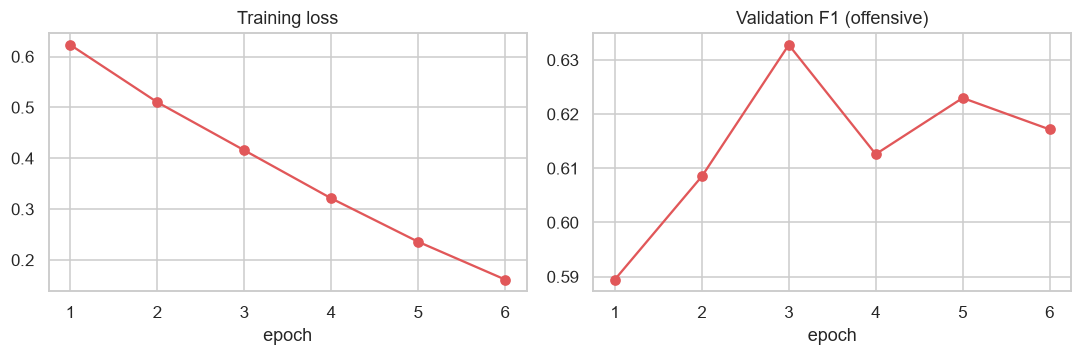

In [46]:
if "BiLSTM" in PRED:                                                  # learning curves of the LSTM
    h = pd.DataFrame(res_lstm["history"])
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    ax[0].plot(h["epoch"], h["train_loss"], marker="o", color=MODEL_COLORS["BiLSTM"]); ax[0].set_title("Training loss")
    ax[1].plot(h["epoch"], h["f1"], marker="o", color=MODEL_COLORS["BiLSTM"]); ax[1].set_title("Validation F1 (offensive)")
    for a in ax: a.set_xlabel("epoch")
    fig.tight_layout(); savefig(fig, P.figures / "bilstm_learning_curves.png"); plt.show()

**Reading.** The loss should fall steadily; the validation F1 should rise then flatten or drop. A growing gap (loss still falling while validation F1 drops) means **overfitting**: that is why the best epoch is kept instead of the last one.

<a id="10"></a>
## 10. Optional advanced model · BERT / DistilBERT  (`src/bert_model.py`)
**Idea.** BERT is a **Transformer pre-trained** on huge text corpora (it already "knows" English). We **fine-tune** it on our 2-class task with a very small learning rate (2e-5), so it adapts without forgetting.
Its **self-attention** lets every word look at every other word, giving true contextual understanding ("that's sick!" vs "I feel sick").
**Choices that matter**
* **Input = the original tweet** (`text`), not the heavily cleaned one: BERT's tokenizer handles punctuation, emojis and casing, and stop-words carry context.
* **Checkpoint**: `distilbert-base-uncased` by default (about half the cost of BERT for ~97% of its quality). Alternatives in `bert_model.py`: `bert-base-uncased`, `roberta-base`, `cardiffnlp/twitter-roberta-base` (pre-trained on tweets, often best).
  Do **not** use `cardiffnlp/twitter-roberta-base-offensive` as your model: it was already fine-tuned on this exact dataset (cite it only as an external reference).
* **Cost**: needs `pip install torch transformers` and internet to download the checkpoint. A GPU is strongly advised (free on Google Colab); on CPU expect 30–60 min.
* Max length **64 tokens** (tweets are short), 3 epochs, batch 32, warm-up then linear decay, gradient clipping, class-weighted loss, best epoch on validation F1.
* The best-epoch model, its tokenizer and its config are **saved** in `models/bert/` so that notebook 06 can score it on the test set without retraining.

In [47]:
if _enabled(RUN_BERT):
    try:
        res_bert = bert_model.train_bert(train[RAW].tolist(), y_train, val[RAW].tolist(), y_val)   # prints one line per epoch
        register("BERT", res_bert["pred"], res_bert["scores"], "optional",
                 {"checkpoint": res_bert["cfg"]["model_name"], "best_epoch": res_bert["best_epoch"],
                  "lr": res_bert["cfg"]["lr"], "epochs": res_bert["cfg"]["epochs"]})
        display(pd.DataFrame(res_bert["history"]).round(4))
        try:                                                           # NEW: keep the best-epoch model for notebook 06
            bert_model.save_bert(res_bert, MODEL_DIR / "bert")
            print("BERT saved ->", (MODEL_DIR / "bert").relative_to(P.root))
        except Exception as err_save:
            print(f"BERT trained but could NOT be saved ({type(err_save).__name__}: {err_save}) -> notebook 06 will not find it.")
    except Exception as err:                                           # no internet, missing package, out of memory...
        print(f"BERT could not run ({type(err).__name__}: {err})")
        print("Check: pip install torch transformers | internet access to download the model | reduce batch_size if out of memory.")
else:
    print("BERT skipped (needs torch + GPU in 'auto' mode). Set RUN_BERT = True, or run this notebook on Google Colab (GPU runtime).")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Class weights: [0.7470846 1.511799 ]
Mixed precision: FP16 enabled
Epoch 1/3 | Loss: 0.5352 | Val F1: 0.7150 | Precision: 0.665 | Recall: 0.773 | LR: 0.000015
Epoch 2/3 | Loss: 0.4077 | Val F1: 0.7258 | Precision: 0.682 | Recall: 0.776 | LR: 0.000007
Epoch 3/3 | Loss: 0.3345 | Val F1: 0.7338 | Precision: 0.676 | Recall: 0.802 | LR: 0.000000

Training completed.
Best epoch: 3
Best validation F1: 0.7338


,epoch,train_loss,accuracy,precision,recall,f1
0,1,0.5352,0.7863,0.6648,0.7734,0.7150
1,2,0.4077,0.7968,0.6820,0.7756,0.7258
2,3,0.3345,0.7983,0.6765,0.8017,0.7338


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT saved -> models\bert


**Reading.** On this task a fine-tuned Transformer usually beats the TF-IDF models by several F1 points, mostly through **higher recall** at similar precision, because it understands context and handles unusual spellings. If the history shows the best epoch is the last one, more epochs might still help; if the F1 drops after epoch 1–2, the model is overfitting.
Remember the epoch was selected on validation, so its score is slightly optimistic, like every other tuned model here.

<a id="11"></a>
## 11. Comparison of all models
Everything below is built from the `PRED` registry: it automatically includes whichever models actually ran. **Required** models are labelled `required`, the others `optional`.

In [48]:
rows = []
for name, d in PRED.items():
    m = compute_metrics(y_val, d["y_pred"])                                   # shared metric function (offensive = 1)
    ap = average_precision_score(y_val, d["scores"]) if d["scores"] is not None else np.nan   # threshold-free quality
    rows.append({"Model": name, "Group": d["group"], "Accuracy": m["accuracy"], "Precision": m["precision"],
                 "Recall": m["recall"], "F1 (offensive)": m["f1"], "AP": ap})
results = (pd.DataFrame(rows).round(4).sort_values("F1 (offensive)", ascending=False).reset_index(drop=True))
display(results)
print(f"{len(results)} models compared | required: {(results.Group == 'required').sum()} | optional: {(results.Group == 'optional').sum()}")

,Model,Group,Accuracy,Precision,Recall,F1 (offensive),AP
0,BERT,optional,0.7983,0.6765,0.8017,0.7338,0.7943
1,BiLSTM,optional,0.7107,0.5651,0.7190,0.6328,0.7031
2,Random Forest,required,0.7719,0.7163,0.5664,0.6326,0.7112
3,Logistic Regression,required,0.7402,0.6247,0.6275,0.6261,0.7144
4,Voting ensemble,optional,0.7424,0.6305,0.6209,0.6257,NaN
5,SGD (modified Huber),optional,0.7409,0.6278,0.6209,0.6243,0.7079
6,SVM (LinearSVC),required,0.7417,0.6303,0.6166,0.6233,0.7113
7,Naive Bayes,required,0.7047,0.5749,0.5686,0.5717,0.6504
8,Complement NB,optional,0.7047,0.5749,0.5686,0.5717,0.6504
9,KNN,required,0.6654,0.5185,0.4880,0.5028,0.5556


10 models compared | required: 5 | optional: 5


**Reading.** Sorted by F1 of the offensive class. **AP** (average precision) ranks models without depending on the 0.5 decision threshold: if two models have the same F1 but different AP, the one with the higher AP is the better *ranker* (a threshold adjustment could improve it).
Compare precision and recall per model: recall above precision = the model flags generously; the opposite = more cautious. Gaps of about one F1 point are within the noise of a 1,324-tweet validation set (see section 12).

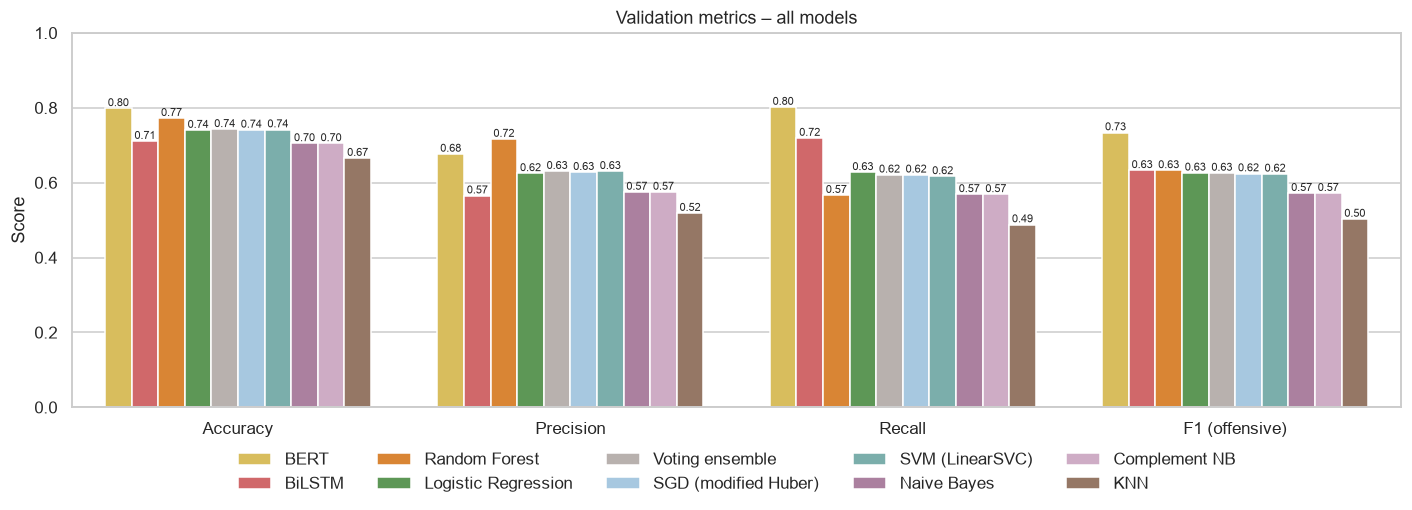

In [49]:
metrics = ["Accuracy", "Precision", "Recall", "F1 (offensive)"]
long = results.melt(id_vars="Model", value_vars=metrics, var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.barplot(data=long, x="Metric", y="Score", hue="Model", hue_order=list(results["Model"]),   # same order as the table
            palette=MODEL_COLORS, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7)                                                    # value on each bar
ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_title("Validation metrics – all models")
ax.legend(title="", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.tight_layout(); savefig(fig, P.figures / "metrics_all_models.png"); plt.show()

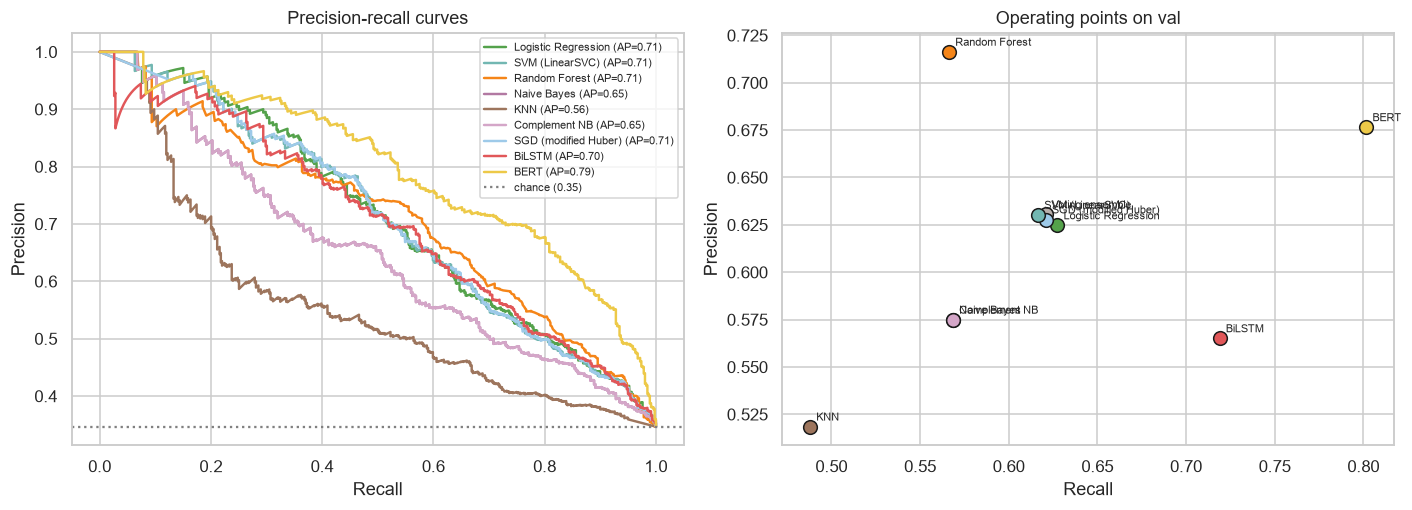

In [50]:
# Left: precision-recall CURVES (every possible threshold). Right: the operating point each model actually uses (threshold 0.5 / 0).
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
for name, d in PRED.items():
    if d["scores"] is not None:                                               # hard-voting has no scores -> no curve
        p, r, _ = precision_recall_curve(y_val, d["scores"])
        a1.plot(r, p, color=MODEL_COLORS[name], lw=1.6, label=f"{name} (AP={average_precision_score(y_val, d['scores']):.2f})")
a1.axhline(y_val.mean(), ls=":", color="grey", label=f"chance ({y_val.mean():.2f})")   # a random classifier's precision
a1.set_xlabel("Recall"); a1.set_ylabel("Precision"); a1.set_title("Precision-recall curves"); a1.legend(fontsize=7)
for _, row in results.iterrows():
    a2.scatter(row["Recall"], row["Precision"], s=80, color=MODEL_COLORS[row["Model"]], edgecolor="k", zorder=3)
    a2.annotate(row["Model"], (row["Recall"], row["Precision"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.set_title("Operating points on val")
fig.tight_layout(); savefig(fig, P.figures / "pr_curves_all_models.png"); plt.show()

**Reading.** A curve that is **higher and to the right** is better. Curves that nearly overlap (typically the linear models) are statistically indistinguishable; a curve far below (KNN) is clearly worse at every threshold.
On the right, each dot is where the model actually operates: moving along a model's own curve (changing its decision threshold) trades precision for recall.

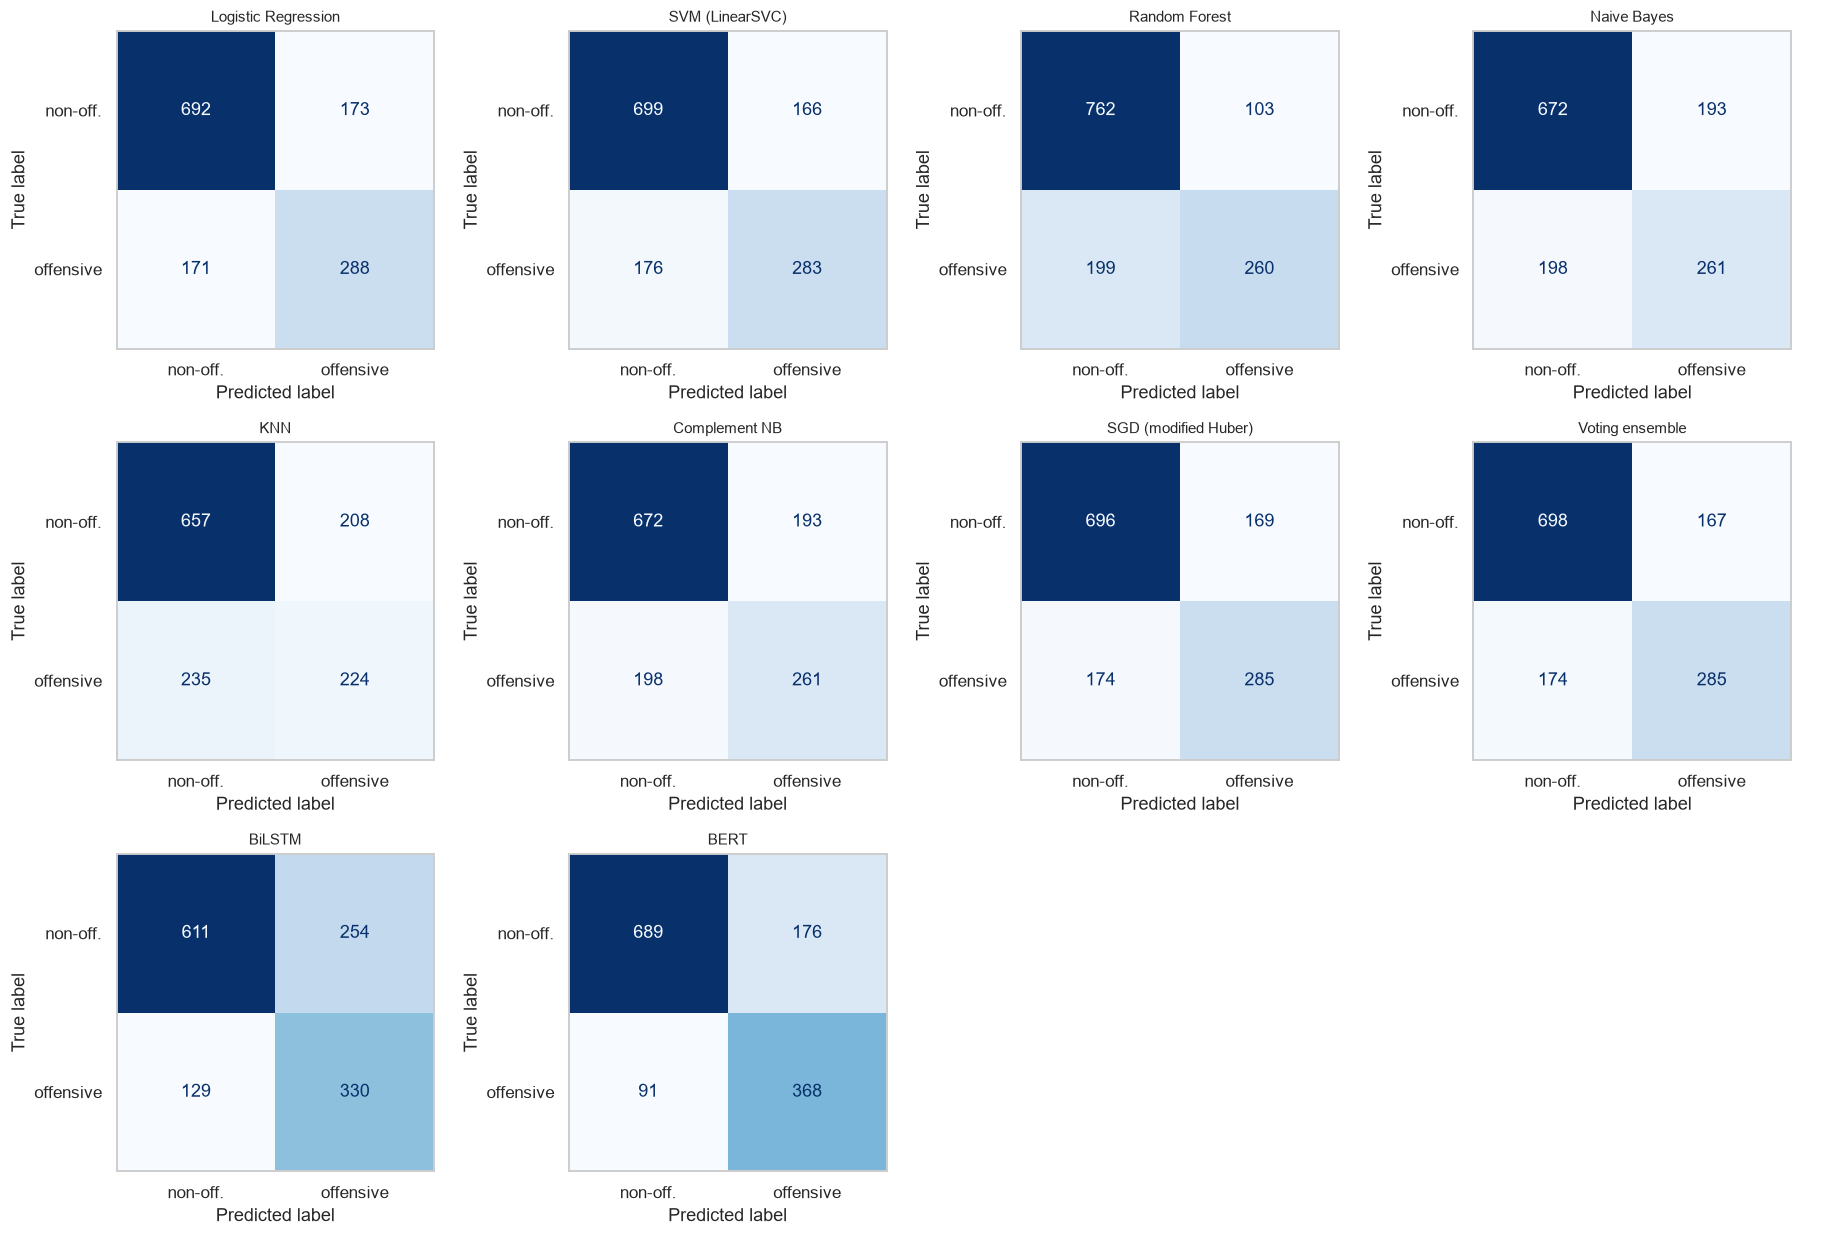

In [51]:
n = len(PRED); cols = 4; rows_ = int(np.ceil(n / cols))                      # grid that fits any number of models
fig, axes = plt.subplots(rows_, cols, figsize=(4.2 * cols, 3.8 * rows_))
for ax, (name, d) in zip(axes.ravel(), PRED.items()):
    ConfusionMatrixDisplay(get_confusion_matrix(y_val, d["y_pred"]),
                           display_labels=["non-off.", "offensive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10); ax.grid(False)
for ax in axes.ravel()[n:]:
    ax.axis("off")                                                           # hide unused panels
fig.tight_layout(); savefig(fig, P.figures / "confusion_all_models.png"); plt.show()

**Reading.** In each matrix, the **bottom-left** cell counts offensive tweets that were missed (false negatives) and the **top-right** cell counts non-offensive tweets wrongly flagged (false positives). The diagonal is correct predictions.

<a id="12"></a>
## 12. Robustness: 5-fold cross-validation (classical models)
The validation score comes from **one** split of 1,324 tweets, so small gaps can be luck. We re-train each classical model (with its tuned hyperparameters) on 5 different train/validation splits **of the training set** and report the **mean ± standard deviation** of F1.
Neural models are excluded (too slow). Small caveat: the TF-IDF was fitted on the whole train set, so IDF weights saw the held-out folds (a minor, standard simplification); KNN is oversampled **inside** each fold.

,Model,F1 mean,F1 std,folds
0,Logistic Regression,0.6188,0.0132,"[0.628, 0.595, 0.634, 0.619, 0.618]"
1,Voting ensemble,0.6169,0.0141,"[0.635, 0.594, 0.628, 0.616, 0.612]"
2,SVM (LinearSVC),0.6149,0.0144,"[0.636, 0.593, 0.624, 0.613, 0.608]"
3,Random Forest,0.5926,0.0109,"[0.604, 0.572, 0.594, 0.595, 0.598]"
4,Naive Bayes,0.5809,0.0089,"[0.595, 0.572, 0.574, 0.576, 0.588]"
5,KNN,0.4918,0.0136,"[0.501, 0.469, 0.487, 0.51, 0.492]"


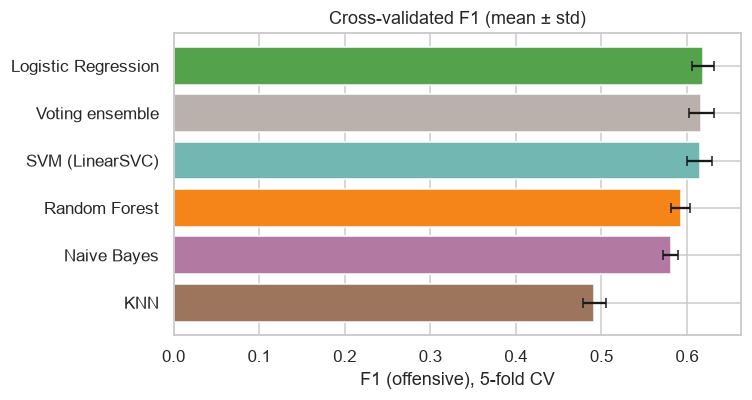

In [52]:
if RUN_CV:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)      # folds keep the 1/3 offensive ratio
    # Factories rebuilding each model with its tuned parameters (a fresh model per fold)
    factories = {
        logistic_regression.NAME: lambda X, y: logistic_regression.train(X, y, C=best_lr_C),
        svm.NAME:                 lambda X, y: svm.train(X, y, C=best_svm_C),
        random_forest.NAME:       lambda X, y: random_forest.train(X, y, **best_rf_params),
        naive_bayes.NAME:         lambda X, y: naive_bayes.train(X, y, alpha=best_nb_alpha),
        knn.NAME:                 lambda X, y: knn.train(X, y, **best_knn_params),   # oversamples inside train()
    }
    if RUN_EXTRA:
        factories[extra_models.NAME_VOTE] = lambda X, y: extra_models.train_voting(X, y, best_lr_C, best_svm_C, best_nb_alpha)
    cv_rows = []
    for name, make in factories.items():
        f1s = []
        for tr, te in skf.split(X_train, y_train):                          # 5 different splits
            model = make(X_train[tr], y_train[tr])                          # train on 4 folds
            f1s.append(compute_metrics(y_train[te], model.predict(X_train[te]))["f1"])   # score on the held-out fold
        cv_rows.append({"Model": name, "F1 mean": np.mean(f1s), "F1 std": np.std(f1s), "folds": np.round(f1s, 3).tolist()})
    cv = pd.DataFrame(cv_rows).sort_values("F1 mean", ascending=False).reset_index(drop=True)
    display(cv.round(4))
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.barh(cv["Model"][::-1], cv["F1 mean"][::-1], xerr=cv["F1 std"][::-1],           # bar = mean, whisker = std
            color=[MODEL_COLORS[m] for m in cv["Model"][::-1]], capsize=3)
    ax.set_xlabel("F1 (offensive), 5-fold CV"); ax.set_title("Cross-validated F1 (mean ± std)")
    fig.tight_layout(); savefig(fig, P.figures / "cv_f1_models.png"); plt.show()
else:
    cv = None; print("RUN_CV = False -> skipped.")

**Reading.** If two models' whiskers overlap, their difference is **not reliable**: treat them as tied and choose on secondary criteria (simplicity, speed, interpretability). A model clearly separated from the rest (typically KNN at the bottom) is genuinely different.

<a id="13"></a>
## 13. What the linear models learned
In a linear model each TF-IDF feature has one weight: large **positive** weights push a tweet towards **offensive**, large **negative** ones towards **non-offensive**. Reading them checks that the models rely on meaningful words (not on artefacts).

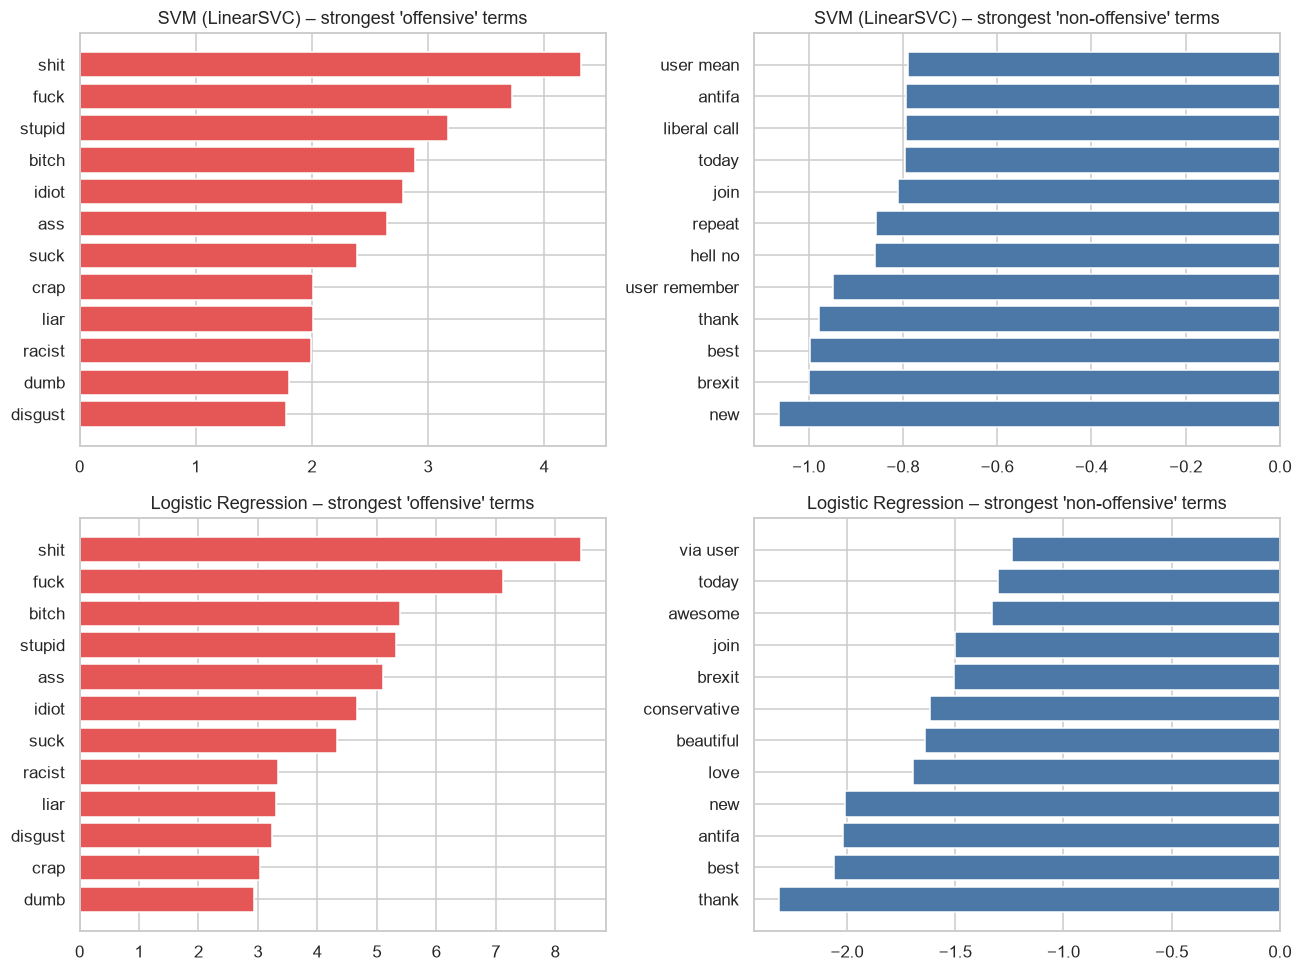

Top-30 'offensive' terms shared by SVM and Logistic Regression: 27 / 30


In [53]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, name in enumerate([svm.NAME, logistic_regression.NAME]):
    off, non = top_linear_terms(MODELS[name], feature_names, n=12)           # strongest terms of each class
    axes[row, 0].barh(off["term"][::-1], off["weight"][::-1], color=COLORS["offensive"])
    axes[row, 0].set_title(f"{name} – strongest 'offensive' terms")
    axes[row, 1].barh(non["term"], non["weight"], color=COLORS["non-offensive"])
    axes[row, 1].set_title(f"{name} – strongest 'non-offensive' terms")
fig.tight_layout(); savefig(fig, P.figures / "linear_models_top_terms.png"); plt.show()

# How much do the two linear models agree? (overlap of their top-30 offensive terms)
t_svm = set(top_linear_terms(MODELS[svm.NAME], feature_names, 30)[0]["term"])
t_lr  = set(top_linear_terms(MODELS[logistic_regression.NAME], feature_names, 30)[0]["term"])
print(f"Top-30 'offensive' terms shared by SVM and Logistic Regression: {len(t_svm & t_lr)} / 30")

**Reading.** Vulgar or insulting words are expected on the offensive side. If **topic words** (political groups, events…) appear, the models partly learn *what people talk about* rather than *how they talk*: a limitation to mention in the project conclusion.
Also check that placeholders left by the cleaning (e.g. `user`) do not dominate either side. A high overlap between the two lists means both models learned essentially the same thing, which explains their similar scores.

<a id="14"></a>
## 14. Conclusions
Generated from the results above, so it stays correct when the notebook is re-run. The final choice of the best model and its justification belong to the evaluation notebook; here we only report what the **validation** results show.
Since hyperparameters (and the best epoch for the neural models) were also selected on validation, these scores are slightly optimistic compared with the test set.

In [54]:
for rank, row in results.iterrows():
    tendency = ("flags offensive tweets generously (recall >= precision)" if row["Recall"] >= row["Precision"]
                else "is more cautious: fewer false alarms, but more offensive tweets missed")
    print(f"{rank + 1:>2}. {row['Model']:<22} [{row['Group']:<8}] F1 = {row['F1 (offensive)']:.3f} "
          f"(P = {row['Precision']:.3f}, R = {row['Recall']:.3f}, AP = {row['AP']:.3f}) -> {tendency}.")

top, bottom = results.iloc[0], results.iloc[-1]
print(f"\nStrongest on val : {top['Model']} (F1 = {top['F1 (offensive)']:.3f})")
print(f"Weakest on val   : {bottom['Model']} (F1 = {bottom['F1 (offensive)']:.3f})")
gap = results.iloc[0]["F1 (offensive)"] - results.iloc[1]["F1 (offensive)"]
print(f"Gap 1st vs 2nd   : {gap:.3f} F1 points" + ("  -> within noise: treat as tied." if gap < 0.015 else ""))

req = results[results.Group == "required"]
print(f"\nRequired models trained : {len(req)} (assignment minimum = 5) -> {'OK' if len(req) >= 5 else 'MISSING MODELS'}")
if (results.Group == "optional").any():
    best_opt = results[results.Group == "optional"].iloc[0]
    delta = best_opt["F1 (offensive)"] - req.iloc[0]["F1 (offensive)"]
    print(f"Best optional model     : {best_opt['Model']} ({delta:+.3f} F1 vs best required model)")
if cv is not None:
    print(f"Most stable in CV       : {cv.sort_values('F1 std').iloc[0]['Model']} (std = {cv['F1 std'].min():.3f})")

 1. BERT                   [optional] F1 = 0.734 (P = 0.676, R = 0.802, AP = 0.794) -> flags offensive tweets generously (recall >= precision).
 2. BiLSTM                 [optional] F1 = 0.633 (P = 0.565, R = 0.719, AP = 0.703) -> flags offensive tweets generously (recall >= precision).
 3. Random Forest          [required] F1 = 0.633 (P = 0.716, R = 0.566, AP = 0.711) -> is more cautious: fewer false alarms, but more offensive tweets missed.
 4. Logistic Regression    [required] F1 = 0.626 (P = 0.625, R = 0.627, AP = 0.714) -> flags offensive tweets generously (recall >= precision).
 5. Voting ensemble        [optional] F1 = 0.626 (P = 0.630, R = 0.621, AP = nan) -> is more cautious: fewer false alarms, but more offensive tweets missed.
 6. SGD (modified Huber)   [optional] F1 = 0.624 (P = 0.628, R = 0.621, AP = 0.708) -> is more cautious: fewer false alarms, but more offensive tweets missed.
 7. SVM (LinearSVC)        [required] F1 = 0.623 (P = 0.630, R = 0.617, AP = 0.711) -> is mor

**Reading.** Typical outcome on TweetEval *offensive*: the linear models (LogReg, SVM, SGD) lead the classical group with scores very close to each other; Random Forest and Naive Bayes follow; KNN is last; the BiLSTM is close to the linear models; a fine-tuned BERT-family model is the one most likely to stand out.
If BERT or the LSTM were skipped, say so explicitly in the report (and explain the hardware reason) rather than leaving them out silently.

<a id="15"></a>
## 15. Saving the results
Exported for the evaluation notebook, which builds the final comparison and the error analysis without retraining the comparison models. The final **classical** model is **not** saved here (notebook 06 refits it on train + validation); the **BiLSTM and BERT best-epoch models are saved** in `models/` so that notebook 06 can score the winner on the test set.

| Item | Location |
|---|---|
| Validation metrics of all models | `results/metrics/05_model_training/models_validation_metrics.csv` |
| Cross-validation table | `results/metrics/05_model_training/cv_f1.csv` |
| Hyperparameters chosen | `results/metrics/05_model_training/best_hyperparameters.csv` |
| Tuning tables | `results/metrics/05_model_training/<model>_tuning.csv` |
| Validation predictions (+ scores) | `results/predictions/05_model_training/val_predictions_<model>.csv` |
| Neural models (best epoch) | `models/bilstm.pt` and `models/bert/` (saved in sections 9 and 10) |
| Figures | `results/figures/05_model_training/*.png` |

In [55]:
import re
slug = lambda s: re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")           # "SVM (LinearSVC)" -> "svm_linearsvc"

results.to_csv(P.metrics / "models_validation_metrics.csv", index=False)     # main comparison table
if cv is not None:
    cv.to_csv(P.metrics / "cv_f1.csv", index=False)                          # cross-validation
pd.DataFrame([{"Model": n, "Group": d["group"], "params": str(d["params"])} for n, d in PRED.items()]
             ).to_csv(P.metrics / "best_hyperparameters.csv", index=False)   # what was chosen on val

tuning = {logistic_regression.NAME: lr_grid, svm.NAME: svm_grid, random_forest.NAME: rf_grid,
          naive_bayes.NAME: nb_grid, knn.NAME: knn_grid}
if RUN_EXTRA and extra_models.NAME_CNB in PRED:
    tuning[extra_models.NAME_CNB], tuning[extra_models.NAME_SGD] = cnb_grid, sgd_grid
for name, table in tuning.items():
    table.to_csv(P.metrics / f"{slug(name)}_tuning.csv", index=False)

for name, d in PRED.items():                                                 # tweet, true label, prediction, score
    out = pd.DataFrame({"text": val[RAW], "y_true": y_val, "y_pred": d["y_pred"]})
    if d["scores"] is not None:
        out["score_offensive"] = d["scores"]
    out.to_csv(PRED_DIR / f"val_predictions_{slug(name)}.csv", index=False)

print("Saved:")
for folder in (P.metrics, PRED_DIR):
    for p in sorted(Path(folder).glob("*.csv")):
        print(" -", p.relative_to(P.root))
for p in (MODEL_DIR / "bilstm.pt", MODEL_DIR / "bert"):                      # NEW: neural models saved in sections 9 / 10
    print(" -", p.relative_to(P.root), "(found)" if p.exists() else "(not found: that model was skipped or not saved)")

Saved:
 - results\metrics\05_model_training\best_hyperparameters.csv
 - results\metrics\05_model_training\complement_nb_tuning.csv
 - results\metrics\05_model_training\cv_f1.csv
 - results\metrics\05_model_training\knn_tuning.csv
 - results\metrics\05_model_training\logistic_regression_tuning.csv
 - results\metrics\05_model_training\models_validation_metrics.csv
 - results\metrics\05_model_training\naive_bayes_tuning.csv
 - results\metrics\05_model_training\random_forest_tuning.csv
 - results\metrics\05_model_training\sgd_modified_huber_tuning.csv
 - results\metrics\05_model_training\svm_linearsvc_tuning.csv
 - results\metrics\05_model_training\svm_tuning.csv
 - results\predictions\05_model_training\val_predictions_bert.csv
 - results\predictions\05_model_training\val_predictions_bilstm.csv
 - results\predictions\05_model_training\val_predictions_complement_nb.csv
 - results\predictions\05_model_training\val_predictions_knn.csv
 - results\predictions\05_model_training\val_predictions_l

**Reading.** The list confirms every file the evaluation notebook can now load. If a model is missing from it, its section was skipped (see the switches in section 1). Notebook 06 needs `models/bert/` (or `models/bilstm.pt`) only when that model is the best one on validation.